In [1]:
# preprocessing

import sys
sys.path.append("../src")

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from preprocessing import to_original, to_minmax, to_clahe

def load(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

df = pd.read_csv("../data/splits/train.csv")
df["path"] = "../" + df["path"]
Path("../results/figures").mkdir(parents=True, exist_ok=True)

methods = [("Original", to_original), ("Min-Max", to_minmax), ("CLAHE", to_clahe)]

In [2]:
# pemilihan sampel gambar

sample = df.sample(300, random_state=0).copy()
sample["contrast"] = [load(p).mean(axis=2).std() for p in sample.path]

low = sample.nsmallest(2, "contrast")
rand = sample.drop(low.index).sample(2, random_state=1)
picked = pd.concat([low, rand])
picked[["path", "label", "contrast"]]

,path,label,contrast
2911,../data/raw/Yellow_Daisy/Yellow_Daisy154.jpg,Yellow_Daisy,28.143206
104,../data/raw/Rose/Rose207.jpg,Rose,30.665387
4560,../data/raw/Marigold/Marigold104.jpg,Marigold,48.608927
2178,../data/raw/indian mallow/indian mallow99.jpg,indian mallow,35.750093


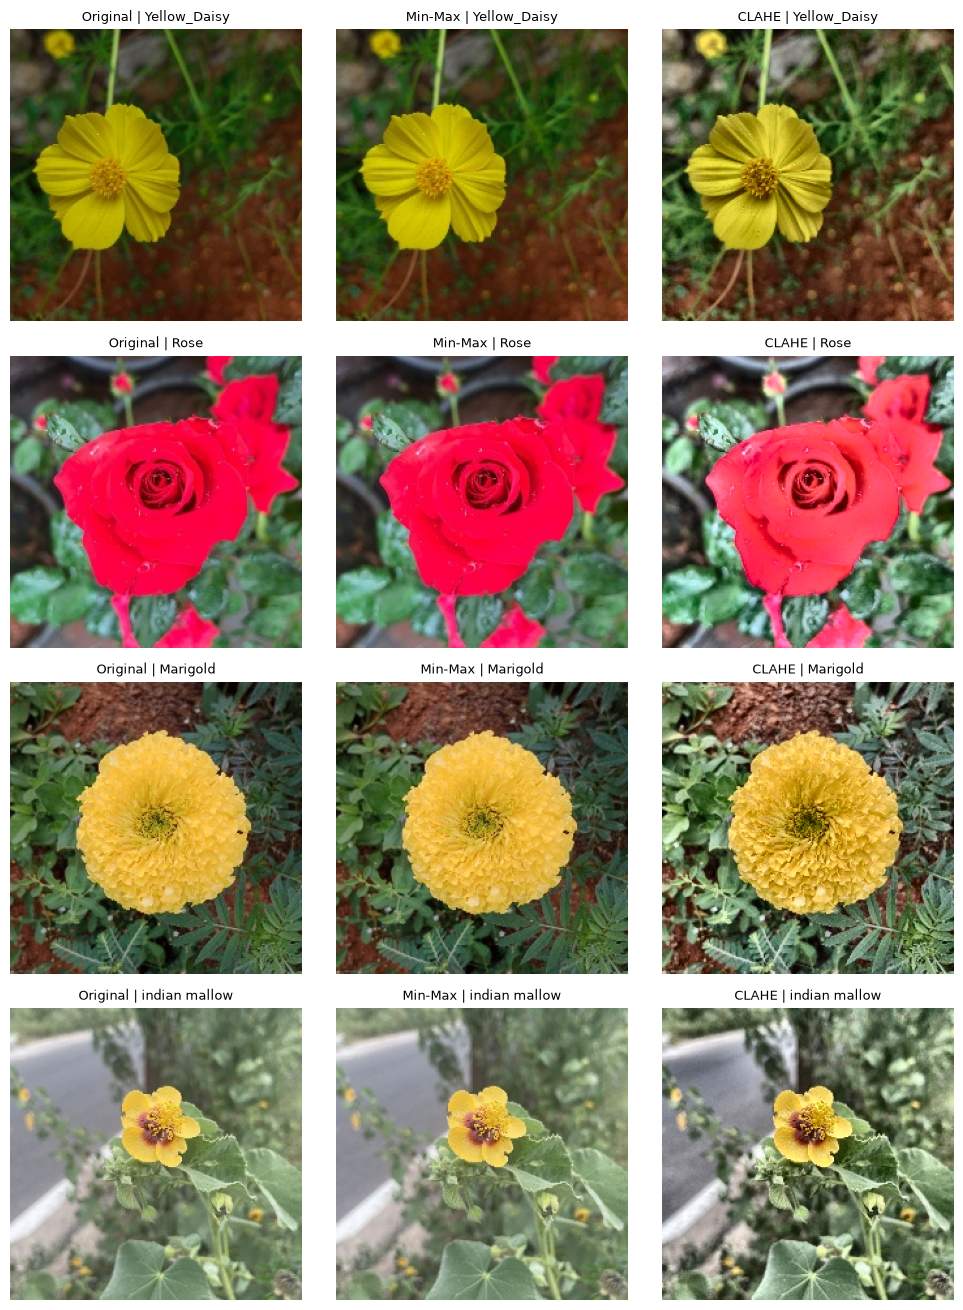

In [3]:
# perbandingan hasil preprocessing

fig, axes = plt.subplots(len(picked), 3, figsize=(10, 3.3 * len(picked)))
for i, (_, row) in enumerate(picked.iterrows()):
    img = load(row.path)
    for j, (name, fn) in enumerate(methods):
        axes[i, j].imshow(fn(img))
        axes[i, j].set_title(f"{name} | {row.label}", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("../results/figures/preprocessing_comparison.png", dpi=200)
plt.show()

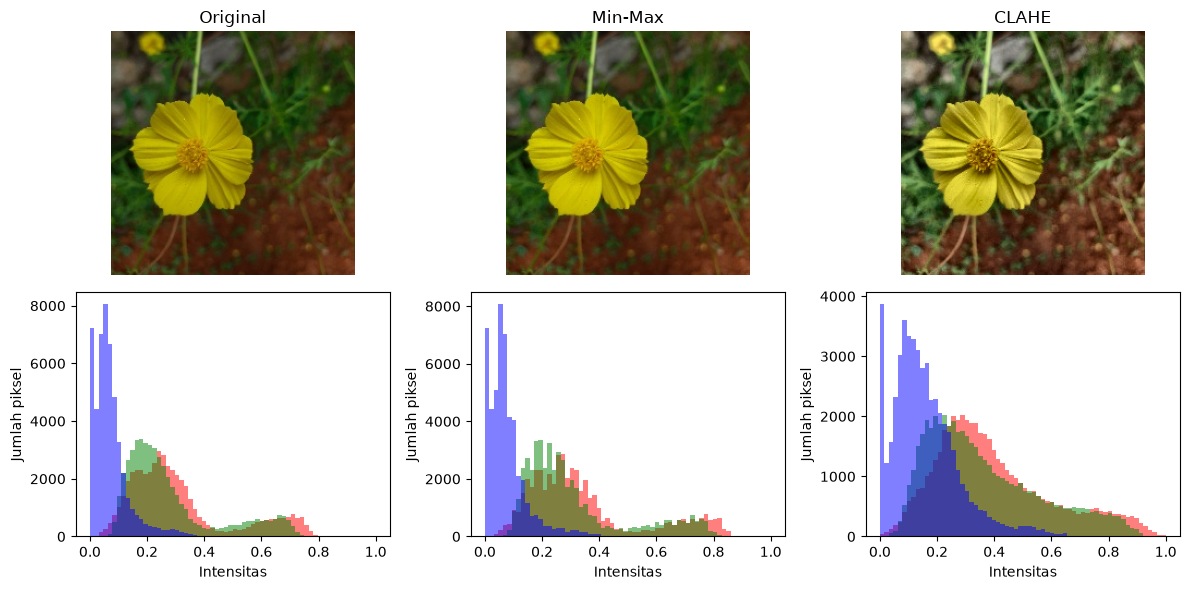

In [4]:
# histogram per channel

img = load(picked.iloc[0].path)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, (name, fn) in enumerate(methods):
    out = fn(img)
    axes[0, j].imshow(out)
    axes[0, j].set_title(name)
    axes[0, j].axis("off")
    for c, col in enumerate("rgb"):
        axes[1, j].hist(out[..., c].ravel(), bins=64, range=(0, 1), color=col, alpha=0.5)
    axes[1, j].set_xlabel("Intensitas")
    axes[1, j].set_ylabel("Jumlah piksel")
plt.tight_layout()
plt.savefig("../results/figures/histogram_comparison.png", dpi=200)
plt.show()